In [1]:
## PACKAGES
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
import umap.umap_ as umap
import torch
import torch.nn.functional as F
import torchvision.transforms as transforms
import timm
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sn
import matplotlib.pyplot as plt

from IPython.display import display, clear_output
import sys
sys.path.insert(1,'C:\Zmyfiles\codes\research\KPCA-DA\KPCA_DA\examples\Scripts')
from pyDeepInsightv3 import ImageTransformer

c:\Users\sheli\anaconda3\envs\SheliaWorkspace\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
##LOAD DATA
expr_file = r"..\Data\cptacvssmc\cptac_labels.csv"
#expr_file = r"..\data\TvsN\TCGA_BRCA_NvT.csv"
#expr_file = r"..\data\Survival_TCGA_VS_Desmd\modified_TCGA_BRCA_log2.csv"
# expr1 = pd.read_csv(expr_file, encoding='utf-8', engine='python')
# expr=expr1.transpose()
# expr.columns=expr.iloc[0]
# X_all = expr.iloc[1:,1:-1].values
# X_all=X_all.astype(float)
# days= expr.iloc[1:,-1].values
# genes = expr.iloc[:,:-1].columns.to_numpy()
expr = pd.read_csv(expr_file, encoding='utf-8', engine='python')
expr=expr.transpose()
expr.columns=expr.iloc[0]
X = expr.iloc[1:,0:-1].values
X=X.astype(float)
Y = expr.iloc[1:,-1].values
genes = expr.iloc[:,:-1].columns.to_numpy()


In [2]:
## Data1
#expr_file1 = r"..\Data\TvsN\TCGA_BRCA_NvT.csv"
expr_file1 = r"..\Data\cptacvssmc\cptac_labels.csv"
#expr_file = r"..\data\Survival_TCGA_VS_Desmd\smc_labels.csv"
# expr1 = pd.read_csv(expr_file, encoding='utf-8', engine='python')
# expr=expr1.transpose()
# expr.columns=expr.iloc[0]
# X_all = expr.iloc[1:,1:-1].values
# X_all=X_all.astype(float)
# days= expr.iloc[1:,-1].values
# genes = expr.iloc[:,:-1].columns.to_numpy()
expr1 = pd.read_csv(expr_file1, encoding='utf-8', engine='python')
expr1=expr1.transpose()
expr1.columns=expr1.iloc[0]
X1 = expr1.iloc[1:,0:-1].values
X1=X1.astype(float)
Y1 = expr1.iloc[1:,-1].values
genes1 = expr1.iloc[:,:-1].columns.to_numpy()

##LOAD DATA2
#expr_file2 = r"..\Data\TvsN\GSE45498_NvT.csv"
expr_file2 = r"..\Data\cptacvssmc\smc_labels.csv"
#expr_file = r"..\data\Survival_TCGA_VS_Desmd\smc_labels.csv"
# expr1 = pd.read_csv(expr_file, encoding='utf-8', engine='python')
# expr=expr1.transpose()
# expr.columns=expr.iloc[0]
# X_all = expr.iloc[1:,1:-1].values
# X_all=X_all.astype(float)
# days= expr.iloc[1:,-1].values
# genes = expr.iloc[:,:-1].columns.to_numpy()
expr2 = pd.read_csv(expr_file2, encoding='utf-8', engine='python')
expr2=expr2.transpose()
expr2.columns=expr2.iloc[0]
X2 = expr2.iloc[1:,0:-1].values
X2=X2.astype(float)
Y2 = expr2.iloc[1:,-1].values
genes2 = expr2.iloc[:,:-1].columns.to_numpy()

In [ ]:
common_genes=[]
for i in genes1:
    for j in genes2:
        if i==j:
            common_genes.append(i)

print(common_genes)



In [ ]:

condition=np.isin(genes2,common_genes)
indexx=np.where(condition)[0]
print(indexx)



In [ ]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device,dtype=torch.long)

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

In [ ]:
X_new=[[0 if np.isnan(x) else x for x in row] for row in X]
np.array(X_new)

## DeepInsight Image Transformation
Convert data to image format using DeepInsight

In [3]:
from sklearn.decomposition import PCA, KernelPCA

In [4]:
# X_train, X_test, y_train, y_test = train_test_split(
#       X, Y, test_size=0.3, random_state=5, stratify=Y)

X_train, X_test, y_train, y_test = X1,X2,Y1,Y2

var_filter1 = X_train.var(0) >= np.percentile(X_train.var(0), 10., method='nearest')
var_filter2 = X_test.var(0) >= np.percentile(X_test.var(0), 10., method='nearest')

mms = MinMaxScaler()
X_train_norm = mms.fit_transform(X_train[:, var_filter1])
X_test_norm = mms.fit_transform(X_test[:, var_filter2])

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

le_mapping = dict(zip(le.transform(le.classes_), le.classes_))
num_classes = np.unique(y_train_enc).size

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
net = timm.create_model('resnet50d', pretrained=True, num_classes=num_classes).to(device)
net = net.to(device)

batch_size=20
preprocess = transforms.Compose([
    transforms.ToTensor(),
    #transforms.Normalize(mean=net.default_cfg['mean'], std=net.default_cfg['std']),
])



In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    net.parameters(), 
    lr=1e-04,
    momentum=0.9,
)

In [7]:
reducer=KernelPCA(n_components=2, kernel='rbf',gamma=.2)

pixel_size = (227,227)

it1 = ImageTransformer(
    feature_extractor=reducer,
    pixels=pixel_size)

it2 = ImageTransformer(
    feature_extractor=reducer,
    pixels=pixel_size)

it1.fit(X_train_norm, y=y_train, plot=False)
it2.fit(X_test_norm, y=y_test, plot=False)

X_train_img = it1.transform(X_train_norm)
X_test_img = it2.transform(X_test_norm)

In [8]:

#defing the data loader
X_train_tensor = torch.stack([preprocess(img) for img in X_train_img]).float().to(device)
y_train_tensor = torch.from_numpy(y_train_enc).long().to(device)
trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

X_test_tensor = torch.stack([preprocess(img) for img in X_test_img]).float().to(device)
y_test_tensor = torch.from_numpy(y_test_enc).long().to(device)
testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)


##training the data using resnet:
net.train()
for epoch in range(50):
    for i, (inputs, labels) in enumerate(trainloader):
        clear_output(wait=True)
        #display(f"Epoch {epoch:03d}, batch {i:03d}")
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        

###testing the data
test_predicted = np.empty(0)
test_true = np.empty(0)
#test_pred = np.empty(0)

net.eval()

with torch.no_grad():
    for i, (inputs, labels) in enumerate(testloader):
        pred = torch.max(net(inputs), dim=1)[1].cpu().detach().numpy()
        test_predicted = np.append(test_predicted, pred)
        test_true = np.append(test_true, labels.cpu().detach().numpy())


#test_pred = (test_predicted > 0.5).astype(int)        

net=net.to(torch.device('cpu'))
with torch.no_grad():
    y_hat = net(X_train_tensor.cpu())
train_predicted=torch.max(y_hat,1)[1]
 

print(f"The train accuracy was {accuracy_score(train_predicted, y_train_enc):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, test_true):.3f}")

        

The train accuracy was 0.718
The test accuracy was 0.283


In [ ]:
test_predicted = np.empty(0)
test_true = np.empty(0)
#test_pred = np.empty(0)
net.fc = nn.Linear(net.fc.in_features, 1)
net.eval()
net=net.to(torch.device('cpu'))


with torch.no_grad():
    for i, (inputs, labels) in enumerate(testloader):
        pred = torch.sigmoid(net(inputs.to(torch.device('cpu')))).cpu().detach().numpy()
        #pred = torch.max(net(inputs), dim=1)[1].cpu().detach().numpy()
        test_predicted = np.append(test_predicted, pred)
        test_true = np.append(test_true, labels.cpu().detach().numpy())


#test_pred = (test_predicted > 0.5).astype(int)        

net=net.to(torch.device('cpu'))
with torch.no_grad():
    y_hat = net(X_train_tensor.cpu())
train_predicted=torch.max(y_hat,1)[1]

In [ ]:
df = pd.DataFrame(test_true)
df.to_csv("true.csv", index=False, header=False)

In [ ]:
df = pd.DataFrame(test_predicted)
df.to_csv("pred_TCGA.csv", index=False, header=False)

SqueezeNet

In [9]:
from sklearn.manifold import TSNE
distance_metric = 'cosine'
reducer=KernelPCA(n_components=2, kernel='rbf',gamma=.099)
# reducer = TSNE(
#     n_components=2,
#     metric=distance_metric,
#     init='random',
#     learning_rate='auto',
#     n_jobs=-1)
# reducer=umap.UMAP(
#     n_components=2,
#     metric=distance_metric,
#     random_state=42,
#     n_neighbors=15,
#     min_dist=0.05,
#     spread=15,
#     low_memory=True,
#     verbose=True,
#     )


pixel_size = (227,227)
it1 = ImageTransformer(
    feature_extractor=reducer,
    pixels=pixel_size)

it2 = ImageTransformer(
  feature_extractor=reducer,
    pixels=pixel_size)

it1.fit(X_train_norm, y=y_train, plot=False)
it2.fit(X_test_norm, y=y_test, plot=False)

X_train_img = it1.transform(X_train_norm)
X_test_img = it2.transform(X_test_norm)

In [10]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

import warnings; 
warnings.simplefilter('ignore')

In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device
model = torchvision.models.squeezenet1_1(weights='DEFAULT')
model.classifier.append(nn.Flatten())
_ = model.classifier.append(nn.Linear(1000, num_classes))

In [12]:
preprocess = transforms.Compose([
    transforms.ToTensor()
])

In [13]:
X_test_tensor1 = torch.stack([preprocess(img) for img in X_test_img]).float()
y_test_tensor1 = torch.from_numpy(le.transform(y_test))

In [107]:
X_train_tensor1 = torch.stack([preprocess(img) for img in X_train_img]).float()
y_train_tensor1 = torch.from_numpy(le.fit_transform(y_train))

In [14]:
X_train_tensor = torch.stack([preprocess(img) for img in X_train_img]).float()
y_train_tensor = torch.from_numpy(le.fit_transform(y_train))

X_test_tensor = torch.stack([preprocess(img) for img in X_test_img]).float()
y_test_tensor = torch.from_numpy(le.transform(y_test))

batch_size = 20

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-04,
    #momentum=0.8,
    weight_decay=1e-04
)

In [15]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device,dtype=torch.long)

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

[0] loss: 1.429
[20] loss: 0.577
[40] loss: 0.215
[60] loss: 0.002
[80] loss: 0.001
[99] loss: 0.000


In [16]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    y_hat = model(X_test_tensor)
test_predicted = torch.max(y_hat, 1)[1]
print(f"The train accuracy was {accuracy_score(train_predicted, y_train_tensor):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, y_test_tensor):.3f}")

The train accuracy was 1.000
The test accuracy was 0.373


In [ ]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    
    y_hat = model(X_test_tensor)
    y_prob_test = torch.sigmoid(y_hat,dim=1)
    test_predicted = (y_prob_test >= 0.5).int()


print(y_prob_test)

### **GRAD_CAM features**

In [124]:
from pyDeepInsightv3 import CAMFeatureSelector
cm_method='GradCAM'
camfs = CAMFeatureSelector(
    model=model,
    it=it1,
    cam_method=cm_method
)

In [125]:
fl_method = "mean"
class_cam = camfs.calculate_class_activations(X_train_tensor, y_train_tensor, batch_size=100, flatten_method=fl_method)

### Select Class-Specific Features
Feature selection for each class is performed by identifying feature indicies mapped to coordinates of the CAM that pass the threshold.

In [133]:
fs_threshold = 0.5
feat_idx, feat_thr,coord= camfs.select_class_features(cams=class_cam, threshold=fs_threshold)

In [ ]:
feat_thr[0]

In [64]:
from pytorch_grad_cam.utils.image import show_cam_on_image
from matplotlib import pyplot as plt

def cam_image(X, y, cam, fs, threshold):
    fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(6,4),
                            constrained_layout=True)
    for cat in np.unique(y):
        cat_idx = np.where(y == cat)[0]
        X_cat = X[cat_idx,:,:,:].detach().mean(dim=0).cpu().numpy()
        cam_cat = cam[cat].copy()
        cam_cat[cam_cat <= threshold] = 0
        visualization = show_cam_on_image(
            np.transpose(X_cat, (1,2,0)),
            cam_cat,
            use_rgb=True
        )
        _ = axs[cat].imshow(visualization)
        axs[cat].text(0,0,le_mapping[cat],c="white",ha="left",va="top",weight="bold",size="x-large")
        axs[cat].text(227,227,f"{fs[cat].shape[0]} genes",c="white",ha="right",va="bottom",weight="bold",size="large")
        axs[cat].axis('off')
    return fig, axs

In [134]:
from pytorch_grad_cam.utils.image import show_cam_on_image
from matplotlib import pyplot as plt

def cam_image2(X, y, cam, fs, threshold):
    fig, axs = plt.subplots(ncols=2, nrows=2, figsize=(8,6),
                            constrained_layout=True)
    for cat in np.unique(y):
        row = cat // 2
        col = cat % 2
        cat_idx = np.where(y == cat)[0]
        X_cat = X[cat_idx,:,:,:].detach().mean(dim=0).cpu().numpy()
        cam_cat = cam[cat].copy()
        cam_cat[cam_cat <= threshold] = 0
        visualization = show_cam_on_image(
            np.transpose(X_cat, (1,2,0)),
            cam_cat,
            use_rgb=True
        )
        _ = axs[row, col].imshow(visualization)
        axs[row, col].text(0,0,le_mapping[cat],c="white",ha="left",va="top",weight="bold",size="x-large")
        axs[row, col].text(227,227,f"{fs[cat].shape[0]} genes",c="white",ha="right",va="bottom",weight="bold",size="large")
        axs[row, col].axis('off')
    return fig, axs

In [ ]:
from pytorch_grad_cam.utils.image import show_cam_on_image
from matplotlib import pyplot as plt

def cam_image3(X):
    fig, axs = plt.subplots(ncols=2, nrows=2, figsize=(8,6),
                            constrained_layout=True)
    for cat in np.unique(4):
        row = cat // 2
        col = cat % 2
        cat_idx = np.where(4 == cat)[0]
        X_cat = X[cat_idx,:,:,:].detach().mean(dim=0).cpu().numpy()
        cam_cat = cam[cat].copy()
        cam_cat[cam_cat <= threshold] = 0
        visualization = show_cam_on_image(
            np.transpose(X_cat, (1,2,0)),
            cam_cat,
            use_rgb=False
        )
        _ = axs[row, col].imshow(np.transpose(X_cat, (1,2,0)))
        axs[row, col].text(0,0,le_mapping[cat],c="white",ha="left",va="top",weight="bold",size="x-large")
        # axs[row, col].text(227,227,f"{fs[cat].shape[0]} genes",c="white",ha="right",va="bottom",weight="bold",size="large")
        axs[row, col].axis('off')
    return fig, axs

In [ ]:
_ = cam_image3(X_train_tensor)

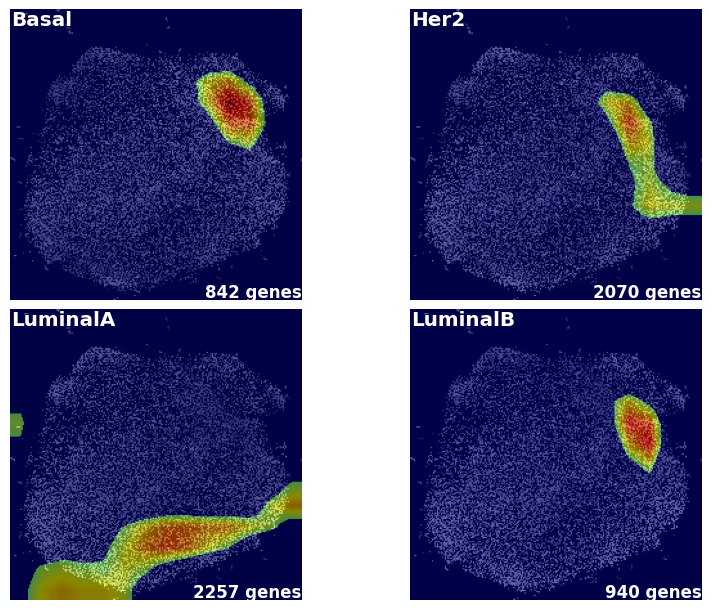

In [135]:
_ = cam_image2(X_train_tensor1, y_train_tensor1.detach().cpu().numpy(), class_cam, feat_idx, fs_threshold)

In [ ]:
for cat, idx in feat_idx.items():
    feature_names = genes2[idx]
    print(f"{idx.shape[0]:5} features selected for {le_mapping[cat]:4}: {', '.join(feature_names[1:10])}...")
    

In [ ]:
#save feature names in a csv file
for cat, idx in feat_idx.items():
    feature_names = genes2[idx]
    df = pd.DataFrame(feature_names)
    df.to_csv(f"features_class_{le_mapping[cat]}.csv", index=False, header=False)

In [ ]:
selected_features_by_class_np = {}  # Dictionary to hold features for each class

for cat, idx in feat_idx.items():
    feature_names = genes2[idx]
    class_name = le_mapping[cat]
    selected_features_by_class_np[class_name] = np.array(feature_names)  # Save as a list


In [ ]:

import numpy as np

# Dictionary of PAM50 genes grouped by subtype
pam50_by_subtype = {
    "LuminalA": [
        "ESR1", "PGR", "BCL2", "BAG1", "MAPT", "MDM2", "MLPH", "NAT1", "SLC39A6", "FOXA1", "ACTR3B", "ANLN", "CDH3", "CENPF", "CEP55", "EXO1", "MYC", "NDC80", "NUF2", "ORC6L", 
        "RRM2", "TMEM45B", "TYMS", "UBE2T"
    ],
    "LuminalB": [
        "MKI67", "CCNB1", "CCNE1", "CDC6", "CDC20", "CDC25A", "UBE2C", "MYBL2", "BIRC5", "ACTR3B", "ANLN", "CDH3", "CENPF", "CEP55", "EXO1", "MYC", "NDC80", "NUF2", "ORC6L", 
        "RRM2", "TMEM45B", "TYMS", "UBE2T"
    ],
    "Her2": [
        "ERBB2", "GRB7", "FGFR4", "GPR160", "ACTR3B", "ANLN", "CDH3", "CENPF", "CEP55", "EXO1", "MYC", "NDC80", "NUF2", "ORC6L", 
        "RRM2", "TMEM45B", "TYMS", "UBE2T"
    ],
    "Basal": [
        "KRT5", "KRT14", "KRT17", "EGFR", "FOXC1", "MIA", "PHGDH", "PTTG1", "MELK", "ACTR3B", "ANLN", "CDH3", "CENPF", "CEP55", "EXO1", "MYC", "NDC80", "NUF2", "ORC6L", 
        "RRM2", "TMEM45B", "TYMS", "UBE2T"
    ],
}

# Convert PAM50 genes to sets
pam50_by_subtype_sets = {
    subtype: set(genes) for subtype, genes in pam50_by_subtype.items()
}

# Assume selected_features_by_class_np = { "Luminal A": np.array([...]), ... }
comparison_results = {}

for subtype, selected_genes_np in selected_features_by_class_np.items():
    # Only compare this subtype with the corresponding PAM50 genes
    selected_genes = set(selected_genes_np.astype(str).tolist())
    if subtype in pam50_by_subtype_sets:
        pam_genes = pam50_by_subtype_sets[subtype]
        overlap = selected_genes & pam_genes
        comparison_results[subtype] = {
            "num_selected": len(selected_genes),
            "num_overlap": len(overlap),
            "overlap_genes": sorted(overlap)
        }

# 🖨️ Print the comparison
for subtype, result in comparison_results.items():
    print(f"\nSubtype: {subtype}")
    print(f"  Total selected genes: {result['num_selected']}")
    print(f"  Overlapping PAM50 genes: {result['num_overlap']}")
    print(f"  Genes: {', '.join(result['overlap_genes']) if result['overlap_genes'] else 'None'}")


 CDH3, CENPF, CEP55, ESR1, MAPT, MYC, NDC80, NUF2, PGR, RRM2, SLC39A6
  BIRC5, CDH3, CENPF, CEP55, MYC, NDC80, NUF2, RRM2


In [ ]:
###For Saving the files

for key, array in selected_features_by_class_np.items():
    # Convert numpy array to DataFrame
    df = pd.DataFrame(array)
    
    # Save to Excel file named after the key
    filename = f"{key}.csv"
    df.to_csv(filename, index=False, header=False)  # You can customize index/header as needed
    
    print(f"Saved {filename}")

### GRAD-CAM with Ranking

In [ ]:
from pyDeepInsightv3 import CAMFeatureSelector

# Initialize Grad-CAM feature selector
camfs = CAMFeatureSelector(
    model=model,
    it=it2,
    cam_method='GradCAM'  # or 'GradCAM++', 'ScoreCAM', etc.
)



In [ ]:
# Calculate class activation maps for all classes
# `flatten_method='mean'` averages over spatial dimensions
class_cam = camfs.calculate_class_activations(
    X_test_tensor,
    y_test_tensor,
    batch_size=100,
    flatten_method='mean'
)

# class_cam is now a 2D NumPy array of shape (num_classes, num_features)
# Each row corresponds to a class; each column to a feature's Grad-CAM score



In [ ]:
# Assuming class_cam shape is (num_classes, num_features)
# and genes2 is a numpy array of gene names, length = num_features
target_class=3
top_k = 200  # Number of top genes to show

# for class_idx in class_cam:
#     feature_scores = class_cam[class_idx]  # Scores for this class

feature_scores = feat_thr[target_class]
ranked_indices=feat_idx[target_class]
ranked_genes = genes2[ranked_indices]
sorted_indices = np.argsort(-feature_scores)
sorted_scores = feature_scores[sorted_indices]
sorted_genes = ranked_genes[sorted_indices]
sorted_index=ranked_indices[sorted_indices]

top200genes=[]

for i in range(top_k):
    # Map indices to gene names
    print(f"Rank {i+1}: Gene {sorted_genes[i]} - Score: {float(sorted_scores[i]):.4f}")
    top200genes.append(sorted_genes[i])

    # print(f"\nClass {class_idx} ({le_mapping[class_idx]}): Top {top_k} genes")
    # for i in range(top_k):
    #
#save top 200 genes in a csv file
df = pd.DataFrame(top200genes)
df.to_csv(f"top200_class_{le_mapping[target_class]}.csv", index=False, header=False)    

In [ ]:
BAG1, CDH3, CENPF, CEP55, ESR1, FOXA1, MAPT, MLPH, MYC, NDC80, NUF2, PGR, RRM2, SLC39A6

### Active Learning on Target Domain
Iteratively select the most informative unlabeled target samples to label and fine-tune the model.
- **Pool**: `X2_adapt` (target domain, labels hidden from the model)
- **Oracle**: `Y2_adapt` (true labels, revealed only when queried)
- **Strategies**: entropy sampling, margin sampling, core-set (greedy k-center)

In [ ]:
from sklearn.metrics import pairwise_distances

# ── Prepare adapt pool images (same domain as X_test, so use var_filter2 + it2) ──
mms_al = MinMaxScaler()
mms_al.fit(X_test[:, var_filter2])                          # fit on test distribution
X_adapt_norm_al = mms_al.transform(X2_adapt[:, var_filter2])
X_adapt_img    = it2.transform(X_adapt_norm_al)             # same pixel layout as X_test_img
y_adapt_enc    = le.transform(Y2_adapt)                     # oracle labels (hidden until queried)

X_adapt_tensor = torch.stack([preprocess(img) for img in X_adapt_img]).float()
y_adapt_tensor = torch.from_numpy(y_adapt_enc).long()

# ── Save source-trained model as the AL baseline ──
net = net.to(device)
al_base_state  = {k: v.clone() for k, v in net.state_dict().items()}

print(f"Pool size : {len(X_adapt_tensor)} samples")
print(f"Test  size: {len(X_test_tensor)} samples")

Pool size : 81 samples
Test  size: 36 samples


Strategy: entropy  |  Rounds: 5  |  Query/round: 10

Round  1 | Target labeled:  10 | Test acc: 0.500
Round  2 | Target labeled:  20 | Test acc: 0.611
Round  3 | Target labeled:  30 | Test acc: 0.750
Round  4 | Target labeled:  40 | Test acc: 0.667
Round  5 | Target labeled:  50 | Test acc: 0.722

 Round | Labeled | Test Acc
---------------------------------------------
     1 |      10 |    0.500
     2 |      20 |    0.611
     3 |      30 |    0.750
     4 |      40 |    0.667
     5 |      50 |    0.722


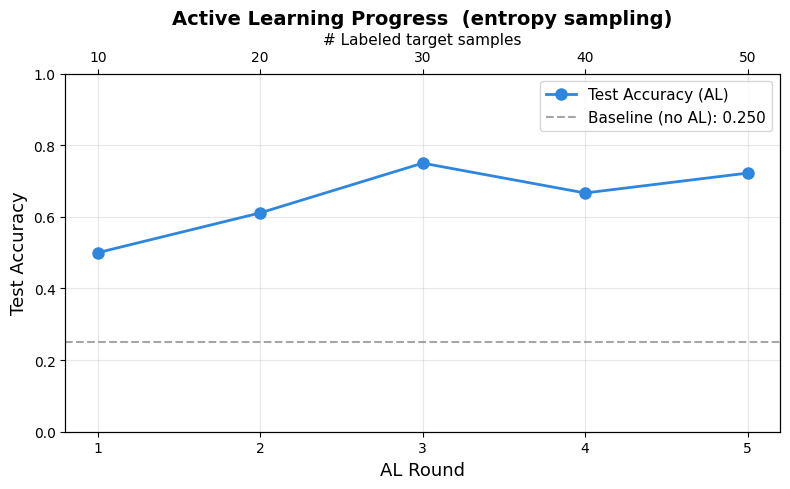

In [ ]:
# ── Query strategies ──────────────────────────────────────────────────────────

def entropy_query(net, X_pool, n_query):
    net.eval()
    with torch.no_grad():
        probs = torch.softmax(net(X_pool.to(device)), dim=1).cpu().numpy()
    entropy = -(probs * np.log(probs + 1e-9)).sum(axis=1)
    return np.argsort(entropy)[-n_query:]            # highest entropy = most uncertain


def margin_query(net, X_pool, n_query):
    net.eval()
    with torch.no_grad():
        probs = torch.softmax(net(X_pool.to(device)), dim=1).cpu().numpy()
    top2  = np.sort(probs, axis=1)[:, -2:]
    margin = top2[:, -1] - top2[:, -2]
    return np.argsort(margin)[:n_query]              # smallest margin = most uncertain


def coreset_query(net, X_labeled, X_pool, n_query):
    """Greedy k-center in embedding space (farthest-first traversal)."""
    def embed(X):
        net.eval()
        with torch.no_grad():
            feat = net.forward_features(X.to(device))
        if feat.dim() > 2:
            feat = feat.mean(dim=[-2, -1])
        return feat.cpu().numpy()

    emb_lab  = embed(X_labeled)
    emb_pool = embed(X_pool)
    dists    = pairwise_distances(emb_pool, emb_lab).min(axis=1)
    selected = []
    for _ in range(n_query):
        idx = int(np.argmax(dists))
        selected.append(idx)
        dists = np.minimum(dists, pairwise_distances(emb_pool, emb_pool[[idx]]).ravel())
    return np.array(selected)


# ── Active learning loop ───────────────────────────────────────────────────────

QUERY_STRATEGY = 'entropy'   # 'entropy' | 'margin' | 'coreset'
N_ROUNDS       = 5
N_QUERY        = 10           # samples labeled per round
FT_EPOCHS      = 30
FT_PATIENCE    = 8

pool_mask          = np.ones(len(X_adapt_tensor), dtype=bool)
labeled_X_list     = []
labeled_y_list     = []
al_results         = []

net.load_state_dict(al_base_state)
net = net.to(device)

print(f"Strategy: {QUERY_STRATEGY}  |  Rounds: {N_ROUNDS}  |  Query/round: {N_QUERY}\n")

for round_i in range(N_ROUNDS):
    pool_idx = np.where(pool_mask)[0]
    X_pool   = X_adapt_tensor[pool_idx]

    # ── Query ──
    if QUERY_STRATEGY == 'entropy':
        local_idx = entropy_query(net, X_pool, N_QUERY)
    elif QUERY_STRATEGY == 'margin':
        local_idx = margin_query(net, X_pool, N_QUERY)
    else:
        X_lab_so_far = (X_train_tensor.cpu() if not labeled_X_list
                        else torch.cat([X_train_tensor.cpu()] + labeled_X_list))
        local_idx = coreset_query(net, X_lab_so_far, X_pool, N_QUERY)

    global_idx = pool_idx[local_idx]
    pool_mask[global_idx] = False

    # ── Oracle reveals labels ──
    labeled_X_list.append(X_adapt_tensor[global_idx])
    labeled_y_list.append(y_adapt_tensor[global_idx])

    # ── Fine-tune: source + all labeled target so far ──
    X_ft = torch.cat([X_train_tensor.cpu()] + labeled_X_list)
    y_ft = torch.cat([y_train_tensor.cpu()] + labeled_y_list)
    ft_loader = DataLoader(TensorDataset(X_ft, y_ft), batch_size=batch_size, shuffle=True)

    net.load_state_dict(al_base_state)      # reset each round for fair comparison
    net = net.to(device)
    ft_opt   = optim.AdamW(net.parameters(), lr=5e-5, weight_decay=1e-4)
    ft_sched = optim.lr_scheduler.CosineAnnealingLR(ft_opt, T_max=FT_EPOCHS)

    best_ft_acc, best_ft_state, patience_ctr = 0.0, None, 0
    net.train()
    for epoch in range(FT_EPOCHS):
        for xb, yb in ft_loader:
            ft_opt.zero_grad()
            criterion(net(xb.to(device)), yb.to(device)).backward()
            ft_opt.step()
        ft_sched.step()

        net.eval()
        preds, trues = [], []
        with torch.no_grad():
            for xb, yb in testloader:
                preds.extend(torch.max(net(xb), 1)[1].cpu().numpy())
                trues.extend(yb.cpu().numpy())
        acc = accuracy_score(trues, preds)

        if acc > best_ft_acc:
            best_ft_acc   = acc
            best_ft_state = {k: v.clone() for k, v in net.state_dict().items()}
            patience_ctr  = 0
        else:
            patience_ctr += 1
        if patience_ctr >= FT_PATIENCE:
            break
        net.train()

    net.load_state_dict(best_ft_state)
    n_labeled = (round_i + 1) * N_QUERY
    al_results.append({'round': round_i + 1, 'n_labeled': n_labeled, 'acc': best_ft_acc})
    print(f"Round {round_i+1:2d} | Target labeled: {n_labeled:3d} | Test acc: {best_ft_acc:.3f}")

# ── Summary ────────────────────────────────────────────────────────────────────
print(f"\n{'='*45}")
print(f"{'Round':>6} | {'Labeled':>7} | {'Test Acc':>8}")
print(f"{'-'*45}")
for r in al_results:
    print(f"{r['round']:>6} | {r['n_labeled']:>7} | {r['acc']:>8.3f}")
print(f"{'='*45}")

# ── Learning curve plot ────────────────────────────────────────────────────────
rounds  = [r['round']     for r in al_results]
accs    = [r['acc']       for r in al_results]
labeled = [r['n_labeled'] for r in al_results]

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(rounds, accs, 'o-', color='#2E86DE', linewidth=2, markersize=8, label='Test Accuracy (AL)')
ax1.axhline(y=testacc, color='gray', linestyle='--', alpha=0.7,
            label=f'Baseline (no AL): {testacc:.3f}')
ax1.set_xlabel('AL Round', fontsize=13)
ax1.set_ylabel('Test Accuracy', fontsize=13)
ax1.set_xticks(rounds)
ax1.set_ylim(0, 1)
ax1.legend(fontsize=11)
ax1.set_title(f'Active Learning Progress  ({QUERY_STRATEGY} sampling)', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twiny()
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(rounds)
ax2.set_xticklabels(labeled)
ax2.set_xlabel('# Labeled target samples', fontsize=11)

plt.tight_layout()
plt.show()